In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r"C:\Users\HC\Downloads\titanic.csv")

In [5]:
print("Dataset rows and Columns:")
print(df.shape)

Dataset rows and Columns:
(891, 12)


In [6]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [7]:
print("Dataset Information:")
df.info()
print("\nStatistical Summary:")
display(df.describe(include="all"))
print("\nColumn Names:")
print(df.columns.tolist())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB

Statistical Summary:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
count,891.000000,891.000000,891.000000,891,891,714.000000,891.000000,891.000000,891,891.000000,204,889
unique,NaN,NaN,NaN,891,2,NaN,NaN,NaN,681,NaN,147,3
top,NaN,NaN,NaN,"Braund, Mr. Owen Harris",male,NaN,NaN,NaN,347082,NaN,G6,S
freq,NaN,NaN,NaN,1,577,NaN,NaN,NaN,7,NaN,4,644
mean,446.000000,0.383838,2.308642,NaN,NaN,29.699118,0.523008,0.381594,NaN,32.204208,NaN,NaN
std,257.353842,0.486592,0.836071,NaN,NaN,14.526497,1.102743,0.806057,NaN,49.693429,NaN,NaN
min,1.000000,0.000000,1.000000,NaN,NaN,0.420000,0.000000,0.000000,NaN,0.000000,NaN,NaN
25%,223.500000,0.000000,2.000000,NaN,NaN,20.125000,0.000000,0.000000,NaN,7.910400,NaN,NaN
50%,446.000000,0.000000,3.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN
75%,668.500000,1.000000,3.000000,NaN,NaN,38.000000,1.000000,0.000000,NaN,31.000000,NaN,NaN



Column Names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


In [8]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [9]:
(df.isnull().mean() * 100).round(2)

PassengerId     0.00
Survived        0.00
Pclass          0.00
Name            0.00
Sex             0.00
Age            19.87
SibSp           0.00
Parch           0.00
Ticket          0.00
Fare            0.00
Cabin          77.10
Embarked        0.22
dtype: float64

In [10]:
 df.duplicated().sum()

np.int64(0)

In [11]:
df.nunique()

PassengerId    891
Survived         2
Pclass           3
Name           891
Sex              2
Age             88
SibSp            7
Parch            7
Ticket         681
Fare           248
Cabin          147
Embarked         3
dtype: int64

In [54]:
quality_report = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2),
    "Unique Values": df.nunique()})

display(quality_report)

,Data Type,Missing Values,Missing Percentage,Unique Values
PassengerId,str,0,0.0,891
Survived,Int64,0,0.0,2
Pclass,Int64,0,0.0,3
Name,str,0,0.0,891
Sex,str,0,0.0,2
Age,float64,0,0.0,88
SibSp,Int64,0,0.0,7
Parch,Int64,0,0.0,7
Ticket,str,0,0.0,681
Fare,float64,0,0.0,248


In [18]:
duplicate_rows = df[df.duplicated()]
display(duplicate_rows)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked


In [19]:
duplicates_removed = df.duplicated().sum()
print("Duplicates Found:", duplicates_removed)

Duplicates Found: 0


In [20]:
df = df.drop_duplicates().copy()

In [21]:
df["Age"] = df["Age"].fillna(df["Age"].median())

In [22]:
df["Fare"] = df["Fare"].fillna(df["Fare"].median())

In [24]:
df["Embarked"] = df["Embarked"].fillna(
    df["Embarked"].mode()[0])

In [25]:
df["Cabin"] = df["Cabin"].fillna("Unknown")

In [26]:
df.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64

In [27]:
df["Sex"] = df["Sex"].astype(str).str.strip().str.lower()
df["Sex"] = df["Sex"].replace({
    "male": "Male",
    "female": "Female",
    "m": "Male",
    "f": "Female"})

In [28]:
df["Embarked"] = (
    df["Embarked"].astype(str).str.strip().str.upper())

In [29]:
print("Sex Values:")
print(df["Sex"].unique())
print("\nEmbarked Values:")
print(df["Embarked"].unique())

Sex Values:
<StringArray>
['Male', 'Female']
Length: 2, dtype: str

Embarked Values:
<StringArray>
['S', 'C', 'Q']
Length: 3, dtype: str


In [30]:
df["PassengerId"] = df["PassengerId"].astype(str)

In [31]:
df["Ticket"] = df["Ticket"].astype(str)

In [32]:
df["Age"] = pd.to_numeric(df["Age"], errors="coerce")

In [33]:
df["Fare"] = pd.to_numeric(df["Fare"], errors="coerce")

In [34]:
integer_columns = ["Survived", "Pclass", "SibSp", "Parch"]
for col in integer_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce").astype("Int64")

In [35]:
df.dtypes

PassengerId        str
Survived         Int64
Pclass           Int64
Name               str
Sex                str
Age            float64
SibSp            Int64
Parch            Int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

In [36]:
numeric_columns = ["Age", "Fare", "SibSp", "Parch"]

In [37]:
Q1_age = df["Age"].quantile(0.25)
Q3_age = df["Age"].quantile(0.75)
print("Q1:", Q1_age)
print("Q3:", Q3_age)

Q1: 22.0
Q3: 35.0


In [38]:
IQR_age = Q3_age - Q1_age
lower_age = Q1_age - 1.5 * IQR_age
upper_age = Q3_age + 1.5 * IQR_age
print("Lower Limit:", lower_age)
print("Upper Limit:", upper_age)

Lower Limit: 2.5
Upper Limit: 54.5


In [40]:
age_outliers = df[
    (df["Age"] < lower_age) |
    (df["Age"] > upper_age)]
print("Age Outliers:", len(age_outliers))

Age Outliers: 66


In [41]:
outlier_report = []
for col in numeric_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    count = ((df[col] < lower) |
            (df[col] > upper)).sum()
    outlier_report.append({
        "Column": col,
        "Lower Limit": lower,
        "Upper Limit": upper,
        "Outliers": count,
        "Decision": "Retained"})
outlier_report = pd.DataFrame(outlier_report)
display(outlier_report)

,Column,Lower Limit,Upper Limit,Outliers,Decision
0,Age,2.500,54.5000,66,Retained
1,Fare,-26.724,65.6344,116,Retained
2,SibSp,-1.500,2.5000,46,Retained
3,Parch,0.000,0.0000,213,Retained


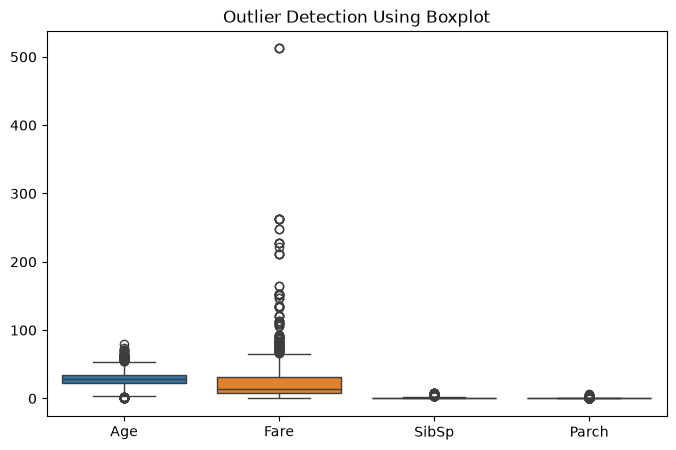

In [42]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df[numeric_columns])

plt.title("Outlier Detection Using Boxplot")
plt.show()


# Data Cleaning Decisions

1. Missing Age values were replaced using median.
2. Missing Fare values were replaced using median.
3. Missing Embarked values were replaced using mode.
4. Missing Cabin values were replaced with "Unknown".
5. Duplicate rows were identified and removed.
6. Sex values were standardized.
7. Embarked values were standardized.
8. PassengerId and Ticket were converted into string data types.
9. Numeric columns were converted into appropriate data types.
10. Outliers were detected using the IQR method.
11. Outliers were retained because they may represent genuine passenger information.


In [43]:
after_rows = len(df)
print("Rows After Cleaning:", after_rows)

Rows After Cleaning: 891


In [44]:
after_nulls = df.isnull().sum().sum()
print("Missing Values After Cleaning:", after_nulls)

Missing Values After Cleaning: 0


In [45]:
after_duplicates = df.duplicated().sum()
print("Duplicates After Cleaning:", after_duplicates)

Duplicates After Cleaning: 0


In [47]:
summary = pd.DataFrame({
    "Metric": [
         "Total Rows",
        "Missing Values",
        "Duplicate Rows" ],
    "Before Cleaning": [
        before_rows,
        before_nulls,
        before_duplicates],
    "After Cleaning": [
        after_rows,
        after_nulls,
        after_duplicates]})
display(summary)

,Metric,Before Cleaning,After Cleaning
0,Total Rows,891,891
1,Missing Values,866,0
2,Duplicate Rows,0,0


In [48]:
expected_types = {
    "PassengerId": "object",
    "Ticket": "object",
    "Age": "float64",
    "Fare": "float64"}
for col, expected in expected_types.items():
    print(
        col,
        "Expected:", expected,
        "| Actual:", str(df[col].dtype),
        "| Correct:", str(df[col].dtype) == expected)

PassengerId Expected: object | Actual: str | Correct: False
Ticket Expected: object | Actual: str | Correct: False
Age Expected: float64 | Actual: float64 | Correct: True
Fare Expected: float64 | Actual: float64 | Correct: True


In [49]:
df.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",Male,22.0,1,0,A/5 21171,7.2500,Unknown,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",Female,26.0,0,0,STON/O2. 3101282,7.9250,Unknown,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",Male,35.0,0,0,373450,8.0500,Unknown,S
5,6,0,3,"Moran, Mr. James",Male,28.0,0,0,330877,8.4583,Unknown,Q
6,7,0,1,"McCarthy, Mr. Timothy J",Male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",Male,2.0,3,1,349909,21.0750,Unknown,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",Female,27.0,0,2,347742,11.1333,Unknown,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",Female,14.0,1,0,237736,30.0708,Unknown,C


In [52]:
df.to_csv("cleaned_titanic.csv", index=False)
print("Cleaned Dataset Saved Successfully!")

Cleaned Dataset Saved Successfully!


In [53]:
import os
print("File Exists:", os.path.exists("cleaned_titanic.csv"))

File Exists: True
